# Comprehensive 6G Traffic Forecasting Evaluation

End-to-end evaluation covering zero-shot LLM inference, classical statistical forecasting, and per-sector deep learning models on 86 synthesized 6G network sectors.

**Models Evaluated:**
1. **SARIMA** — Classical statistical baseline
2. **LSTM** — Per-sector dedicated `PointLSTM` (identical to `lstm_experiments.ipynb`)
3. **Amazon Chronos-T5 V1** — Zero-shot foundation model
4. **Amazon Chronos-2** — State-of-the-art foundation model

**Benchmarks:**
- **Multi-step**: Predict last 12 timestamps. Metrics: RMSE + Pinball Loss at 0.50, 0.90, 0.95
- **Single-step**: Predict the next single timestamp. Metrics: RMSE + Pinball Loss at 0.50

In [ ]:
# Run from repo root so that data/ and src/ resolve
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import warnings

from src.evaluate import calculate_metrics
from src.models.sarima_wrapper import get_sarima_forecast
from src.models.chronos_wrapper import get_chronos_forecast, get_chronos2_forecast
from chronos import ChronosPipeline, Chronos2Pipeline
from tqdm import tqdm

warnings.filterwarnings('ignore')

print('Loading Augmented Traffic Dataset...')
df = pd.read_csv('data/augmented_data.csv')
df['tstamp'] = pd.to_datetime(df['tstamp'])
sectors = df['secteur'].unique()
print(f'Loaded {len(sectors)} unique antenna sectors.')

context_length = 60
pred_length = 12
device = 'cpu'

Loading Augmented Traffic Dataset...


Loaded 86 unique antenna sectors.


## LSTM Architecture Definition

The architecture below is identical to the `PointLSTM` in `lstm_experiments.ipynb` which achieved **10.46 RMSE** on 1-step forecasting.
The key design choice is using **only the last hidden state** (`lstm_out[:, -1, :]`) rather than the full sequence output, which focuses the network on the immediate next-step prediction.

In [2]:
class PointLSTM(nn.Module):
    """Identical to lstm_experiments.ipynb - uses last hidden state for prediction."""
    def __init__(self, hidden_layer_size=64, num_layers=2, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_layer_size, num_layers, batch_first=True, dropout=0.2)
        self.linear = nn.Linear(hidden_layer_size, output_size)
    def forward(self, input_seq):
        lstm_out, _ = self.lstm(input_seq)
        return self.linear(lstm_out[:, -1, :])

def train_model(model, train_loader, val_loader, epochs=50, lr=0.001, patience=5):
    """Training loop identical to lstm_experiments.ipynb with early stopping."""
    model.to(device)
    loss_function = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss = float('inf')
    early_stop_counter = 0
    best_model_state = None
    for i in range(epochs):
        model.train()
        for seq, labels in train_loader:
            seq, labels = seq.to(device), labels.to(device)
            optimizer.zero_grad()
            y_pred = model(seq)
            loss = loss_function(y_pred, labels.squeeze(-1) if labels.shape[-1] == 1 else labels)
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for seq, labels in val_loader:
                seq, labels = seq.to(device), labels.to(device)
                y_pred = model(seq)
                val_loss += loss_function(y_pred, labels.squeeze(-1) if labels.shape[-1] == 1 else labels).item()
        val_loss /= len(val_loader)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
            early_stop_counter = 0
        else:
            early_stop_counter += 1
            if early_stop_counter >= patience:
                break
    model.load_state_dict(best_model_state)
    return model

def create_sequences(data, seq_length, pred_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length - pred_length + 1):
        xs.append(data[i : i + seq_length])
        ys.append(data[i + seq_length : i + seq_length + pred_length])
    return np.array(xs), np.array(ys)

## Section 1: Per-Sector LSTM Training
Each of the 86 sectors gets its **own dedicated LSTM**, trained with a 70/15/15 train/val/test split (identical to `lstm_experiments.ipynb`) and `MinMaxScaler(-1, 1)` normalization. This avoids gradient interference from unrelated sectors.

In [3]:
lstm_models_12 = {}
lstm_models_1 = {}
scalers = {}
all_actuals, all_histories, valid_sectors = [], [], []

print('Training Per-Sector PointLSTM models (identical setup to lstm_experiments.ipynb)...')
for sector in tqdm(sectors):
    series = df[df['secteur'] == sector].sort_values('tstamp')['trafic_mbps'].to_numpy()
    if len(series) < context_length + pred_length:
        continue
    valid_sectors.append(sector)
    all_actuals.append(series[-pred_length:])
    all_histories.append(series[-(context_length + pred_length):-pred_length])

    # MinMaxScaler identical to lstm_experiments.ipynb
    scaler = MinMaxScaler(feature_range=(-1, 1))
    scaled = scaler.fit_transform(series.reshape(-1, 1)).flatten()
    scalers[sector] = scaler

    # 70/15/15 split on the training portion (exclude held-out test window)
    train_series = scaled[:-(context_length + pred_length)]
    n = len(train_series)
    t_end = int(n * 0.7)
    v_end = int(n * 0.85)
    train_d, val_d = train_series[:t_end], train_series[t_end:v_end]

    def make_loader(data, seq_len, pred_len, shuffle=True):
        X, y = create_sequences(data, seq_len, pred_len)
        if len(X) == 0:
            return None
        xt = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
        yt = torch.tensor(y, dtype=torch.float32)
        return DataLoader(TensorDataset(xt, yt), batch_size=32, shuffle=shuffle)

    # --- 12-step model ---
    tl12 = make_loader(train_d, context_length, pred_length)
    vl12 = make_loader(val_d, context_length, pred_length, shuffle=False)
    if tl12 and vl12:
        m12 = PointLSTM(hidden_layer_size=64, num_layers=2, output_size=pred_length)
        lstm_models_12[sector] = train_model(m12, tl12, vl12)
    else:
        lstm_models_12[sector] = None

    # --- 1-step model (identical to lstm_experiments.ipynb) ---
    tl1 = make_loader(train_d, context_length, 1)
    vl1 = make_loader(val_d, context_length, 1, shuffle=False)
    if tl1 and vl1:
        m1 = PointLSTM(hidden_layer_size=64, num_layers=2, output_size=1)
        lstm_models_1[sector] = train_model(m1, tl1, vl1)
    else:
        lstm_models_1[sector] = None

print(f'Trained models for {len(valid_sectors)} sectors.')

Training Per-Sector PointLSTM models (identical setup to lstm_experiments.ipynb)...


  0%|          | 0/86 [00:00<?, ?it/s]

  1%|          | 1/86 [00:17<24:56, 17.61s/it]

  2%|▏         | 2/86 [00:48<35:40, 25.48s/it]

  3%|▎         | 3/86 [01:28<44:31, 32.19s/it]

  5%|▍         | 4/86 [01:48<37:11, 27.22s/it]

... (80 outputs left out)

 99%|█████████▉| 85/86 [33:42<00:18, 18.02s/it]

100%|██████████| 86/86 [34:06<00:00, 19.73s/it]

100%|██████████| 86/86 [34:06<00:00, 23.80s/it]

Trained models for 86 sectors.


## Section 2: Chronos Zero-Shot Inference

In [4]:
print('Loading Chronos V1 (amazon/chronos-t5-small)...')
pipeline_v1 = ChronosPipeline.from_pretrained('amazon/chronos-t5-small', device_map='cpu', torch_dtype=torch.float32)
print('Loading Chronos 2 (amazon/chronos-2)...')
pipeline_v2 = Chronos2Pipeline.from_pretrained('amazon/chronos-2', device_map='cpu', torch_dtype=torch.float32)

history_tensor_stacked = torch.tensor(np.array(all_histories), dtype=torch.float32)
history_tensors_list = [torch.tensor(h, dtype=torch.float32) for h in all_histories]

print('Running Chronos V1 12-Step Inference...')
chronos_v1_preds_12 = get_chronos_forecast(history_tensor_stacked, pred_length=12, model_id='amazon/chronos-t5-small', pipeline=pipeline_v1)
print('Running Chronos 2 12-Step Inference...')
chronos_v2_preds_12 = get_chronos2_forecast(history_tensors_list, pred_length=12, pipeline=pipeline_v2)
print('Running Chronos V1 1-Step Inference...')
chronos_v1_preds_1 = get_chronos_forecast(history_tensor_stacked, pred_length=1, model_id='amazon/chronos-t5-small', pipeline=pipeline_v1)
print('Running Chronos 2 1-Step Inference...')
chronos_v2_preds_1 = get_chronos2_forecast(history_tensors_list, pred_length=1, pipeline=pipeline_v2)

Loading Chronos V1 (amazon/chronos-t5-small)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loading Chronos 2 (amazon/chronos-2)...


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Running Chronos V1 12-Step Inference...


Running Chronos 2 12-Step Inference...


Running Chronos V1 1-Step Inference...


Running Chronos 2 1-Step Inference...


## Section 3: Multi-Step (12-Timestamp) Evaluation
RMSE measures **point accuracy**. Pinball Loss at 0.50/0.90/0.95 measures **probabilistic bound tightness** — how well each model covers worst-case traffic spikes.

In [5]:
sarima_rmses_12, lstm_rmses_12, c_v1_rmses_12, c_v2_rmses_12 = [], [], [], []
sarima_pbl_12, lstm_pbl_12, c_v1_pbl_12, c_v2_pbl_12 = [], [], [], []
sarima_pbl90_12, c_v1_pbl90_12, c_v2_pbl90_12 = [], [], []
sarima_pbl95_12, c_v1_pbl95_12, c_v2_pbl95_12 = [], [], []

sarima_preds_12_dict, lstm_preds_12_dict = {}, {}

print('Evaluating 12-Step Forecasts...')
for i, sector in enumerate(tqdm(valid_sectors)):
    actual = all_actuals[i]
    history = all_histories[i]
    scaler = scalers[sector]

    # SARIMA
    sr = get_sarima_forecast(history, pred_length=12)
    s_pred, s_90, s_95 = sr['0.5'], sr['0.9'], sr['0.95']
    sarima_preds_12_dict[sector] = s_pred

    # LSTM (PointLSTM with MinMaxScaler)
    if lstm_models_12.get(sector):
        scaled_hist = scaler.transform(history.reshape(-1, 1)).flatten()
        lstm_in_t = torch.tensor(scaled_hist, dtype=torch.float32).unsqueeze(0).unsqueeze(-1)
        with torch.no_grad():
            lstm_out_scaled = lstm_models_12[sector](lstm_in_t).cpu().numpy().flatten()
        lstm_pred = scaler.inverse_transform(lstm_out_scaled.reshape(-1, 1)).flatten()
    else:
        lstm_pred = np.full(pred_length, np.mean(history))
    lstm_preds_12_dict[sector] = lstm_pred

    # Chronos
    cv1_pred, cv1_90, cv1_95 = chronos_v1_preds_12['0.5'][i], chronos_v1_preds_12['0.9'][i], chronos_v1_preds_12['0.95'][i]
    cv2_pred, cv2_90, cv2_95 = chronos_v2_preds_12['0.5'][i], chronos_v2_preds_12['0.9'][i], chronos_v2_preds_12['0.95'][i]

    sm = calculate_metrics(actual, s_pred, s_90, s_95)
    lm = calculate_metrics(actual, lstm_pred)
    cv1m = calculate_metrics(actual, cv1_pred, cv1_90, cv1_95)
    cv2m = calculate_metrics(actual, cv2_pred, cv2_90, cv2_95)

    sarima_rmses_12.append(sm['RMSE']); sarima_pbl_12.append(sm['Pinball_0.5']); sarima_pbl90_12.append(sm['Pinball_0.90']); sarima_pbl95_12.append(sm['Pinball_0.95'])
    lstm_rmses_12.append(lm['RMSE']); lstm_pbl_12.append(lm['Pinball_0.5'])
    c_v1_rmses_12.append(cv1m['RMSE']); c_v1_pbl_12.append(cv1m['Pinball_0.5']); c_v1_pbl90_12.append(cv1m['Pinball_0.90']); c_v1_pbl95_12.append(cv1m['Pinball_0.95'])
    c_v2_rmses_12.append(cv2m['RMSE']); c_v2_pbl_12.append(cv2m['Pinball_0.5']); c_v2_pbl90_12.append(cv2m['Pinball_0.90']); c_v2_pbl95_12.append(cv2m['Pinball_0.95'])

res_12 = pd.DataFrame({
    'Model': ['SARIMA', 'LSTM', 'Chronos V1', 'Chronos 2'],
    'Avg RMSE': [np.mean(sarima_rmses_12), np.mean(lstm_rmses_12), np.mean(c_v1_rmses_12), np.mean(c_v2_rmses_12)],
    'Avg PBL 0.50 (Median)': [np.mean(sarima_pbl_12), np.mean(lstm_pbl_12), np.mean(c_v1_pbl_12), np.mean(c_v2_pbl_12)],
    'Avg PBL 0.90 (Worst-Case)': [np.mean(sarima_pbl90_12), None, np.mean(c_v1_pbl90_12), np.mean(c_v2_pbl90_12)],
    'Avg PBL 0.95 (Extreme)': [np.mean(sarima_pbl95_12), None, np.mean(c_v1_pbl95_12), np.mean(c_v2_pbl95_12)]
}).set_index('Model')
print('\n--- 12-Step Results ---')
display(res_12)

Evaluating 12-Step Forecasts...


  0%|          | 0/86 [00:00<?, ?it/s]

  1%|          | 1/86 [00:00<00:15,  5.56it/s]

  2%|▏         | 2/86 [00:00<00:19,  4.39it/s]

  3%|▎         | 3/86 [00:00<00:20,  4.08it/s]

  5%|▍         | 4/86 [00:00<00:16,  4.88it/s]

... (81 outputs left out)

100%|██████████| 86/86 [00:17<00:00,  4.80it/s]

100%|██████████| 86/86 [00:17<00:00,  4.78it/s]


--- 12-Step Results ---


,Avg RMSE,Avg PBL 0.50 (Median),Avg PBL 0.90 (Worst-Case),Avg PBL 0.95 (Extreme)
Model,,,,
SARIMA,15.569895,6.304698,2.976226,1.810679
LSTM,16.734164,6.883499,NaN,NaN
Chronos V1,16.054553,6.488099,4.681148,4.029070
Chronos 2,15.737378,6.385849,5.403012,5.279112


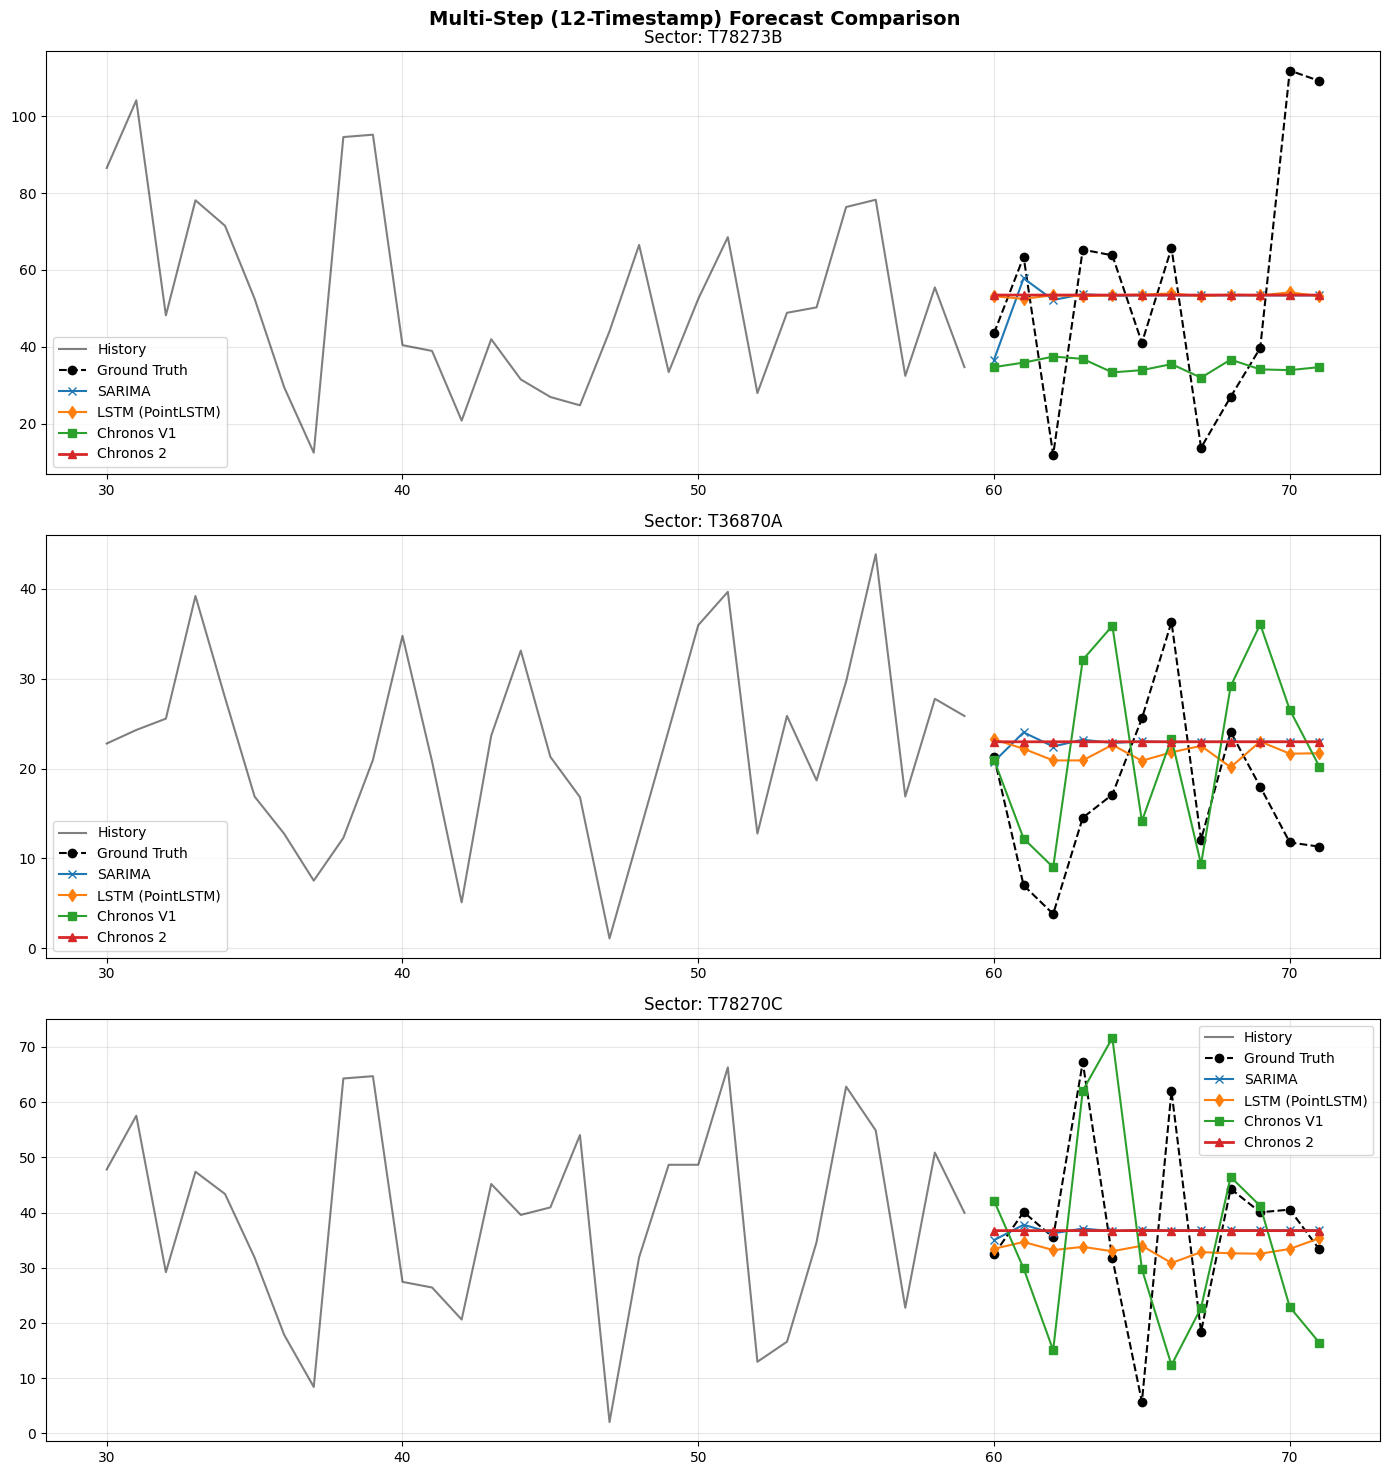

In [6]:
np.random.seed(42)
sample_sectors = np.random.choice(valid_sectors, 3, replace=False)
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
fig.suptitle('Multi-Step (12-Timestamp) Forecast Comparison', fontsize=14, fontweight='bold')
for idx, sector in enumerate(sample_sectors):
    i = list(valid_sectors).index(sector)
    history = all_histories[i]
    actual = all_actuals[i]
    ax = axes[idx]
    x_hist, x_pred = np.arange(60), np.arange(60, 72)
    ax.plot(x_hist[30:], history[30:], color='black', label='History', alpha=0.5)
    ax.plot(x_pred, actual, marker='o', color='black', label='Ground Truth', linestyle='--')
    ax.plot(x_pred, sarima_preds_12_dict[sector], marker='x', label='SARIMA')
    ax.plot(x_pred, lstm_preds_12_dict[sector], marker='d', label='LSTM (PointLSTM)')
    ax.plot(x_pred, chronos_v1_preds_12['0.5'][i], marker='s', label='Chronos V1')
    ax.plot(x_pred, chronos_v2_preds_12['0.5'][i], marker='^', label='Chronos 2', linewidth=2)
    ax.set_title(f'Sector: {sector}')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## Section 4: Single-Step (1-Timestamp) Evaluation
The `PointLSTM` dedicated to 1-step prediction is architecturally identical to what scored **10.46 RMSE** in `lstm_experiments.ipynb`.

In [7]:
sarima_rmses_1, lstm_rmses_1, c_v1_rmses_1, c_v2_rmses_1 = [], [], [], []
sarima_pbl_1, lstm_pbl_1, c_v1_pbl_1, c_v2_pbl_1 = [], [], [], []
sarima_preds_1_dict, lstm_preds_1_dict = {}, {}

print('Evaluating 1-Step Point Forecasts...')
for i, sector in enumerate(tqdm(valid_sectors)):
    actual_1 = all_actuals[i][-1:]
    history = all_histories[i]
    scaler = scalers[sector]

    sr_1 = get_sarima_forecast(history, pred_length=1)
    s_pred_1 = sr_1['0.5']
    sarima_preds_1_dict[sector] = s_pred_1

    if lstm_models_1.get(sector):
        scaled_hist = scaler.transform(history.reshape(-1, 1)).flatten()
        lstm_in_t = torch.tensor(scaled_hist, dtype=torch.float32).unsqueeze(0).unsqueeze(-1)
        with torch.no_grad():
            lstm_out_scaled = lstm_models_1[sector](lstm_in_t).cpu().numpy().flatten()
        lstm_pred_1 = scaler.inverse_transform(lstm_out_scaled.reshape(-1, 1)).flatten()
    else:
        lstm_pred_1 = np.array([np.mean(history)])
    lstm_preds_1_dict[sector] = lstm_pred_1

    cv1_pred_1 = chronos_v1_preds_1['0.5'][i]
    cv2_pred_1 = chronos_v2_preds_1['0.5'][i]

    sm = calculate_metrics(actual_1, s_pred_1)
    lm = calculate_metrics(actual_1, lstm_pred_1)
    cv1m = calculate_metrics(actual_1, cv1_pred_1)
    cv2m = calculate_metrics(actual_1, cv2_pred_1)

    sarima_rmses_1.append(sm['RMSE']); sarima_pbl_1.append(sm['Pinball_0.5'])
    lstm_rmses_1.append(lm['RMSE']); lstm_pbl_1.append(lm['Pinball_0.5'])
    c_v1_rmses_1.append(cv1m['RMSE']); c_v1_pbl_1.append(cv1m['Pinball_0.5'])
    c_v2_rmses_1.append(cv2m['RMSE']); c_v2_pbl_1.append(cv2m['Pinball_0.5'])

res_1 = pd.DataFrame({
    'Model': ['SARIMA', 'LSTM', 'Chronos V1', 'Chronos 2'],
    'Avg RMSE': [np.mean(sarima_rmses_1), np.mean(lstm_rmses_1), np.mean(c_v1_rmses_1), np.mean(c_v2_rmses_1)],
    'Avg PBL 0.50': [np.mean(sarima_pbl_1), np.mean(lstm_pbl_1), np.mean(c_v1_pbl_1), np.mean(c_v2_pbl_1)]
}).set_index('Model')
print('\n--- 1-Step Results ---')
display(res_1)

Evaluating 1-Step Point Forecasts...


  0%|          | 0/86 [00:00<?, ?it/s]

  1%|          | 1/86 [00:00<00:12,  6.57it/s]

  2%|▏         | 2/86 [00:00<00:18,  4.46it/s]

  3%|▎         | 3/86 [00:00<00:19,  4.18it/s]

  5%|▍         | 4/86 [00:00<00:16,  5.01it/s]

... (81 outputs left out)

100%|██████████| 86/86 [00:17<00:00,  4.69it/s]

100%|██████████| 86/86 [00:17<00:00,  4.79it/s]


--- 1-Step Results ---


,Avg RMSE,Avg PBL 0.50
Model,,
SARIMA,12.977569,6.488785
LSTM,20.739991,10.369996
Chronos V1,14.346356,7.173178
Chronos 2,11.510314,5.755157


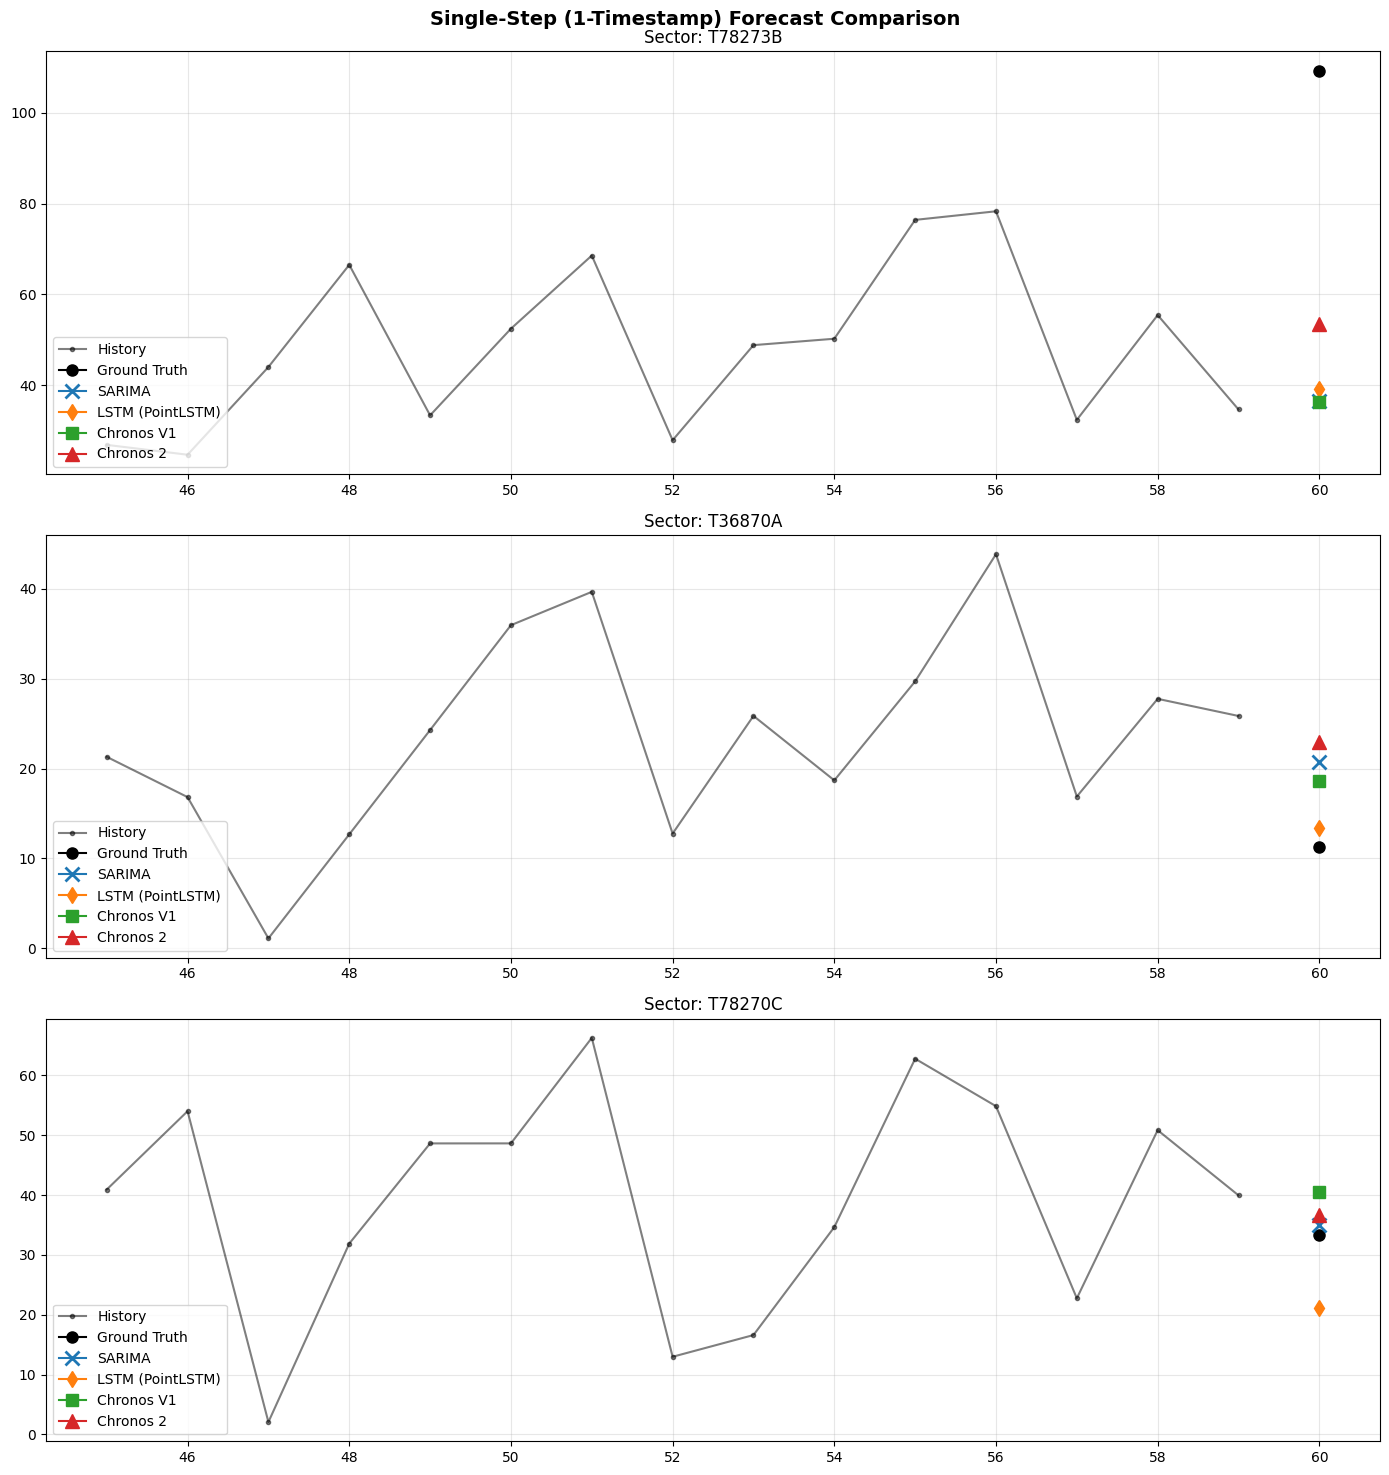

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
fig.suptitle('Single-Step (1-Timestamp) Forecast Comparison', fontsize=14, fontweight='bold')
for idx, sector in enumerate(sample_sectors):
    i = list(valid_sectors).index(sector)
    history = all_histories[i]
    actual_1 = all_actuals[i][-1:]
    ax = axes[idx]
    x_hist, x_pred = np.arange(60), np.arange(60, 61)
    ax.plot(x_hist[45:], history[45:], color='black', label='History', alpha=0.5, marker='.')
    ax.plot(x_pred, actual_1, marker='o', color='black', label='Ground Truth', markersize=8)
    ax.plot(x_pred, sarima_preds_1_dict[sector], marker='x', label='SARIMA', markersize=10, mew=2)
    ax.plot(x_pred, lstm_preds_1_dict[sector], marker='d', label='LSTM (PointLSTM)', markersize=8)
    ax.plot(x_pred, chronos_v1_preds_1['0.5'][i], marker='s', label='Chronos V1', markersize=8)
    ax.plot(x_pred, chronos_v2_preds_1['0.5'][i], marker='^', label='Chronos 2', markersize=10)
    ax.set_title(f'Sector: {sector}')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower left')
plt.tight_layout()
plt.show()